In [ ]:
# LIBS
import zipfile
from google.colab import drive, files

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# DATA LOADING & SETUP

# load
Zip_data_path = "/content/drive/MyDrive/Plant_Disease_Dataset/trainset.zip"
Zip_test_path = "/content/drive/MyDrive/Plant_Disease_Dataset/testset.zip"
Extracted_path = "/content/DATASET"

drive.mount('/content/drive')

with zipfile.ZipFile(Zip_data_path, 'r') as zip_ref:
    zip_ref.extractall(Extracted_path)

with zipfile.ZipFile(Zip_test_path, 'r') as zip_ref:
    zip_ref.extractall(Extracted_path)

print("Data has been loaded successfully!")

# setup
Data_Path = "/content/DATASET/TRAINSET"
Test_Path = "/content/DATASET/TESTSET"
Image_size = (224, 224)
Batch = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    Data_Path,
    validation_split=0.2,
    label_mode="int",
    seed=296,
    image_size=Image_size,
    batch_size=Batch,
    subset="training"
)
valid_ds = tf.keras.utils.image_dataset_from_directory(
    Data_Path,
    validation_split=0.2,
    label_mode="int",
    seed=296,
    image_size=Image_size,
    batch_size=Batch,
    subset="validation"
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    Data_Path,
    label_mode="int",
    seed=296,
    image_size=Image_size,
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Datasets are ready to use!")

Mounted at /content/drive
Data has been loaded successfully!
Found 17888 files belonging to 12 classes.
Using 14311 files for training.
Found 17888 files belonging to 12 classes.
Using 3577 files for validation.
Found 17888 files belonging to 12 classes.
Datasets are ready to use!


In [ ]:
# MOBILENETV2 UNTUNNED MODEL
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.models.Model(inputs, output)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']
)

model.summary()

# model fitting
model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10
)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_3 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_3 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 85s 72ms/step - accuracy: 0.8005 - loss: 0.6415 - val_accuracy: 0.8982 - val_loss: 0.3365
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.8917 - loss: 0.3338 - val_accuracy: 0.9147 - val_loss: 0.2683
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.9089 - loss: 0.2743 - val_accuracy: 0.9226 - val_loss: 0.2452
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.9180 - loss: 0.2480 - val_accuracy: 0.9248 - val_loss: 0.2345
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 39s 24ms/step - accuracy: 0.9236 - loss: 0.2248 - val_accuracy: 0.9198 - val_loss: 0.2314
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 41s 23ms/step - accuracy: 0.9308 - loss: 0.2062 - val_accuracy: 0.9318 - val_loss: 0.2083
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9337 - loss: 0.1985 - val_accuracy: 0.9220 - val_loss: 0.2313
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9402 - loss: 0.1809 - 

559/559 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step
Accuracy is:  96.2 %
Confusion Matrix:
 [[ 938    4    0    2    0    0    0    0    0    0    0    0]
 [   6 1426    0    0    0    0    0    0    0    0    0    0]
 [   1    2 2004   29    1    1   47   11   20   10    0    1]
 [   0    0    6  547    9    0   23   10   16    0    2    0]
 [   1    0    1   54 1826    4    8    6    7    0    0    2]
 [   0    0    2   17    6  883   15   21    3    2    3    0]
 [   0    0   16   22    2    1 1695   13   21    0    1    0]
 [   0    1    0    5    0    0    4 1582   46    1    4    1]
 [   0    0    4   14    0    0   18   59 1275    0    0    2]
 [   0    0    7    1    2    2    0   28    9 3132    3    0]
 [   0    0    0    0    0    0    3    1    0    0  345    0]
 [   0    0    1    0    0    0    2   14   24    0    1 1549]]
Classification Report:
                precision    recall  f1-score   support

           0       0.99      0.99      0.99       944
           1       1.00   

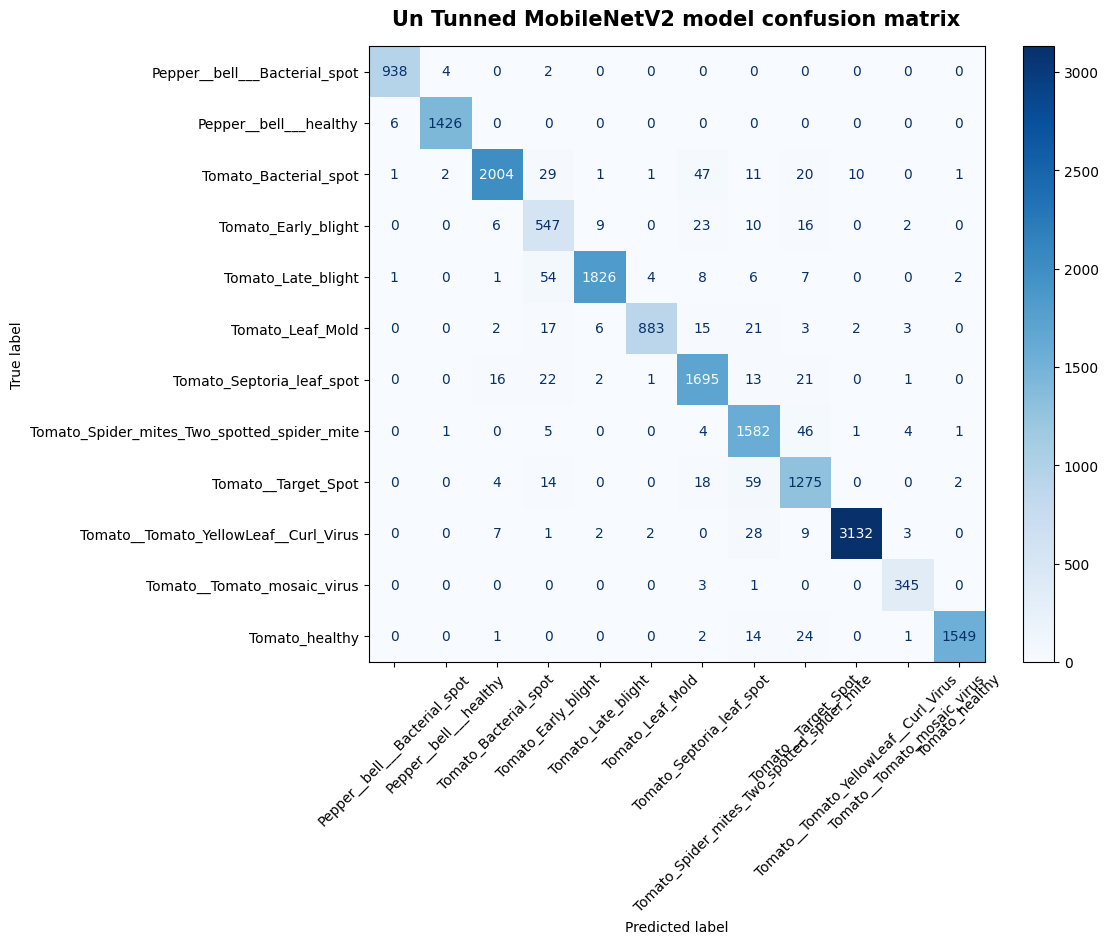

In [ ]:
# model evaluation
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

y_true = np.concatenate([y.numpy() for x, y in test_ds])

ac = accuracy_score(y_true, y_pred) * 100
cr = classification_report(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))

print("Accuracy is: ", round(ac, 1), "%")
print("Confusion Matrix:\n", cm)
print("Classification Report:\n ", cr)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d", xticks_rotation=45, colorbar=True, ax=ax)
plt.title("Un Tunned MobileNetV2 model confusion matrix", fontsize=15, fontweight="bold", pad=15)
plt.show()